# Librerías científicas · Redes neuronales

Ejercicios de [El Libro De Python](https://ellibrodepython.com/red-neuronal-tensorflow) sobre una red neuronal convolucional que reconoce dígitos escritos a mano (MNIST) con `tensorflow`/`keras`. El entrenamiento tarda unos minutos en CPU.

## 1. Datos

Cargar MNIST, normalizar las imágenes a $[0, 1]$, darles forma 28 × 28 × 1 y codificar las etiquetas en *one-hot*. Juntar después entrenamiento y prueba para entrenar con todos los datos.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras.layers import Conv2D, Dense, Flatten, Input, MaxPooling2D
from tensorflow.keras.utils import to_categorical

(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
X = np.concatenate([X_train, X_test]).reshape(-1, 28, 28, 1) / 255.0
y = to_categorical(np.concatenate([y_train, y_test]))
print(X.shape, y.shape)


       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
   16384/11490434 ━━━━━━━━━━━━━━━━━━━━ 49s 4us/step
   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 37s 3us/step
   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 35s 3us/step
  131072/11490434 ━━━━━━━━━━━━━━━━━━━━ 26s 2us/step
  180224/11490434 ━━━━━━━━━━━━━━━━━━━━ 22s 2us/step
  262144/11490434 ━━━━━━━━━━━━━━━━━━━━ 17s 2us/step
  401408/11490434 ━━━━━━━━━━━━━━━━━━━━ 12s 1us/step
  573440/11490434 ━━━━━━━━━━━━━━━━━━━━ 9s 1us/step 
  868352/11490434 ━━━━━━━━━━━━━━━━━━━━ 6s 1us/step
 1327104/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
 2064384/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
 3137536/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
 4866048/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
 7405568/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
 9814016/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(70000, 28, 28, 1) (70000, 10)


## 2. Entrenar con un 1 % de validación y guardar el modelo

Entrenar la red usando solo un 1 % de los datos para validación (`validation_split=0.01`) y comparar su *accuracy* con la de la validación original (≈ 99.2 % con el conjunto de prueba). Guardar el modelo en disco y cargarlo al inicio si ya existe, para no entrenarlo cada vez.

In [2]:
RUTA_MODELO = "mnist_cnn.keras"

def crea_modelo():
    modelo = keras.Sequential([
        Input(shape=(28, 28, 1)),
        Conv2D(32, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(64, activation="relu"),
        Dense(10, activation="softmax"),
    ])
    modelo.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return modelo

if os.path.exists(RUTA_MODELO):
    modelo = keras.models.load_model(RUTA_MODELO)
else:
    keras.utils.set_random_seed(42)
    modelo = crea_modelo()
    historia = modelo.fit(X, y, epochs=2, batch_size=128, validation_split=0.01, verbose=0)
    print("accuracy de validación (1 %):", round(historia.history["val_accuracy"][-1], 4))
    modelo.save(RUTA_MODELO)
cargado = keras.models.load_model(RUTA_MODELO)
print("modelo cargado:", cargado.count_params(), "parámetros")

accuracy de validación (1 %): 0.9871
modelo cargado: 121930 parámetros


Con tan pocos datos de validación (700 imágenes) la estimación de la *accuracy* es más ruidosa, pero el modelo entrena con un 14 % más de datos.

## 3. Predecir un número dibujado

Dibujar un número, convertirlo a 28 × 28 píxeles y predecirlo con el modelo. Aquí el "papel" es una imagen creada con `Pillow` (con una foto real habría que convertirla a escala de grises, invertirla y reducirla igual).

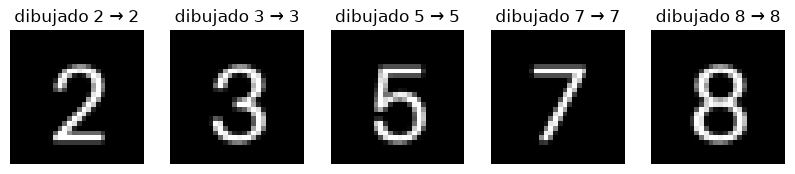

In [3]:
from PIL import Image, ImageDraw, ImageFont

def dibuja_digito(digito, tamaño=280):
    lienzo = Image.new("L", (tamaño, tamaño), color=255)
    ImageDraw.Draw(lienzo).text((tamaño * 0.28, tamaño * 0.05), str(digito), fill=0, font=ImageFont.load_default(size=int(tamaño * 0.8)))
    return lienzo

def prepara(imagen):
    # MNIST: fondo negro, trazo blanco, 28x28
    pequeña = np.array(imagen.convert("L").resize((28, 28))) / 255.0
    return (1 - pequeña).reshape(1, 28, 28, 1)

fig, ejes = plt.subplots(1, 5, figsize=(10, 2.5))
for eje, digito in zip(ejes, (2, 3, 5, 7, 8)):
    entrada = prepara(dibuja_digito(digito))
    prediccion = int(np.argmax(cargado.predict(entrada, verbose=0)))
    eje.imshow(entrada.reshape(28, 28), cmap="gray")
    eje.set_title(f"dibujado {digito} → {prediccion}")
    eje.axis("off")
plt.show()